# Mapeo de agua superficial con radar SAR (NISAR) – Perú
**Machine Learning (por píxel) vs Deep Learning (U-Net con transfer learning)**

Zona de entrenamiento y prueba: **Lima** (escena NISAR 24-oct-2026) · Zona de prueba externa: **Tumbes**

Estructura del notebook
1. Lectura de datos
2. Preprocesamiento (etiqueta, filtros, variables, parches, partición 80/20, normalización)
3. Modelos de Machine Learning (cada pixel = una fila)
4. Modelos de Deep Learning (U-Net: CNN desde cero, VGG16 y ResNet50 con transfer learning)
5. Comparación final ML vs DL
6. Prueba externa en Tumbes (zona que ningún modelo vio)

> **Etiqueta:** clase *agua* (80) de ESA WorldCover. **WorldCover NO se usa como variable de entrada** (sería trampa); solo como etiqueta.
> **Objetivo de esta versión:** agua superficial en general. Los parámetros están bajos a propósito para ver resultados rápido; luego se afinan.

## 0. Librerías

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import rasterio
from rasterio.enums import Resampling
from scipy.ndimage import median_filter, uniform_filter

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, jaccard_score, roc_auc_score)

# ---- Modelos de Machine Learning (los de clase + ensembles)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# ---- Deep Learning (Keras, igual que en clase)
import keras
from keras import layers
from keras.applications import VGG16, ResNet50
from keras.applications.vgg16 import preprocess_input as prep_vgg
from keras.applications.resnet50 import preprocess_input as prep_resnet

warnings.filterwarnings("ignore")
SEED = 2025
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
plt.rcParams["figure.dpi"] = 100

# Carpeta donde se guardan las figuras para el informe
CARPETA_FIG = Path("figuras_informe")
CARPETA_FIG.mkdir(exist_ok=True)
def guardar(nombre):
    plt.savefig(CARPETA_FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")

## 1. Lectura de datos
Cada escena NISAR ya está convertida a GeoTIFF (backscatter **HH en dB**, 5 m de resolución).
Junto a ella hay un **DEM** (elevación) y **WorldCover** (cobertura de suelo) alineados píxel a píxel.

La escena completa de Lima tiene ~105 millones de píxeles, así que al leerla la **reducimos 4 veces** (5 m → 20 m) promediando.
Eso además reduce el *speckle* (ruido granular típico del radar).

In [2]:
RUTA = Path("D:/UNIVERSIDAD ESAN/CICLO 9/JEFFERSON GS/MACHINE LEARNING/Data/Data/procesado/nisar")
FACTOR = 4      # 5 m -> 20 m
P = 128         # tamaño de parche (para deep learning y para la partición)

def leer(ruta, remuestreo):
    with rasterio.open(ruta) as src:
        h, w = src.height // FACTOR, src.width // FACTOR
        return src.read(1, out_shape=(h, w), resampling=remuestreo).astype("float32")

def leer_zona(ciudad, fecha):
    hh  = leer(RUTA / ciudad / f"hh_{fecha}.tif", Resampling.average)
    dem = leer(RUTA / ciudad / "dem.tif",         Resampling.average)
    wc  = leer(RUTA / ciudad / "worldcover.tif",  Resampling.nearest)
    return hh, dem, wc

t0 = time.time()
hh, dem, wc = leer_zona("lima", "20261024")
print(f"Lectura Lima: {time.time()-t0:.1f} s")

Lectura Lima: 12.7 s


In [3]:
print("Forma de las capas:", hh.shape, dem.shape, wc.shape)
print(f"HH  (dB): min {np.nanmin(hh):.1f} | media {np.nanmean(hh):.1f} | max {np.nanmax(hh):.1f} | NaN {np.isnan(hh).mean():.2%}")
print(f"DEM (m) : min {np.nanmin(dem):.1f} | media {np.nanmean(dem):.1f} | max {np.nanmax(dem):.1f} | NaN {np.isnan(dem).mean():.2%}")
clases = {10:"Árboles",20:"Arbustos",30:"Pasto",40:"Cultivo",50:"Urbano",60:"Suelo desnudo/árido",80:"AGUA",90:"Humedal"}
pd.DataFrame({"clase WorldCover": [clases.get(int(c), c) for c in np.unique(wc)],
              "% del área": (np.unique(wc, return_counts=True)[1] / wc.size * 100).round(2)})

Forma de las capas: (2783, 2361) (2783, 2361) (2783, 2361)
HH  (dB): min -26.5 | media -7.9 | max 35.4 | NaN 0.00%
DEM (m) : min 19.4 | media 449.3 | max 2902.4 | NaN 0.00%


,clase WorldCover,% del área
0,Árboles,1.41
1,Arbustos,3.14
2,Pasto,3.13
3,Cultivo,0.41
4,Urbano,25.30
5,Suelo desnudo/árido,43.88
6,AGUA,22.69
7,Humedal,0.05


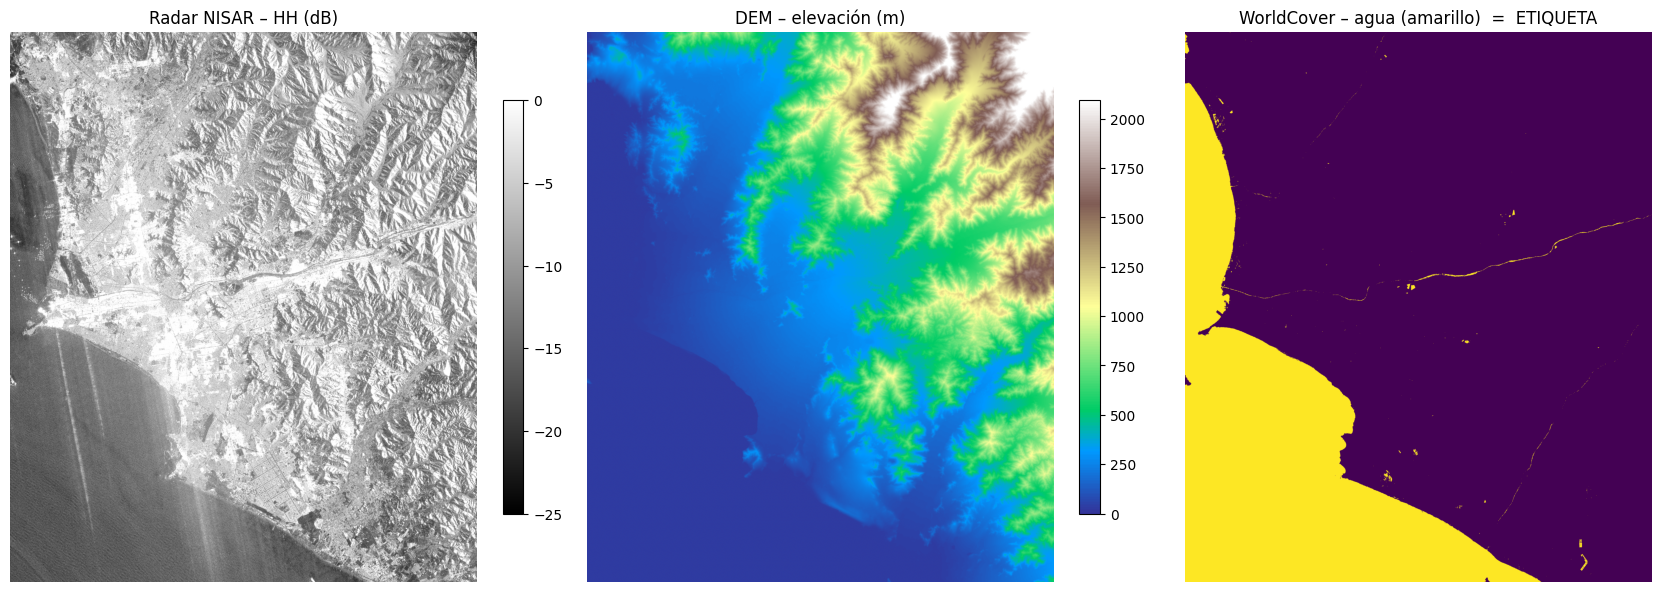

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
im = ax[0].imshow(hh, cmap="gray", vmin=-25, vmax=0);  ax[0].set_title("Radar NISAR – HH (dB)");  plt.colorbar(im, ax=ax[0], fraction=0.04)
im = ax[1].imshow(dem, cmap="terrain", vmin=0, vmax=np.nanpercentile(dem, 99));  ax[1].set_title("DEM – elevación (m)");  plt.colorbar(im, ax=ax[1], fraction=0.04)
im = ax[2].imshow(wc == 80, cmap="viridis");  ax[2].set_title("WorldCover – agua (amarillo)  =  ETIQUETA")
for a in ax: a.axis("off")
plt.tight_layout(); guardar("01_capas_originales"); plt.show()

## 2. Preprocesamiento
### 2.1 Etiqueta y balance de clases
`etiqueta = 1` donde WorldCover dice *agua*, `0` en el resto.

Píxeles agua: 1,490,828  (22.7%)   |   no agua: 5,079,835


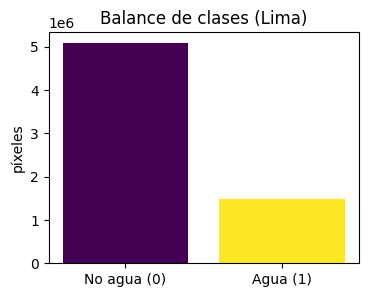

In [5]:
etiqueta = (wc == 80).astype("uint8")
valido = np.isfinite(hh) & np.isfinite(dem)

n_agua, n_no = int(etiqueta[valido].sum()), int((1 - etiqueta[valido]).sum())
print(f"Píxeles agua: {n_agua:,}  ({n_agua/(n_agua+n_no):.1%})   |   no agua: {n_no:,}")
plt.figure(figsize=(4, 3)); plt.bar(["No agua (0)", "Agua (1)"], [n_no, n_agua], color=["#440154", "#fde725"])
plt.title("Balance de clases (Lima)"); plt.ylabel("píxeles"); guardar("02_balance_clases"); plt.show()

### 2.2 ¿El radar separa el agua? (histograma HH)
El agua lisa refleja la señal lejos del satélite → se ve **oscura** (HH muy bajo). Esa es la base física de todo el proyecto.

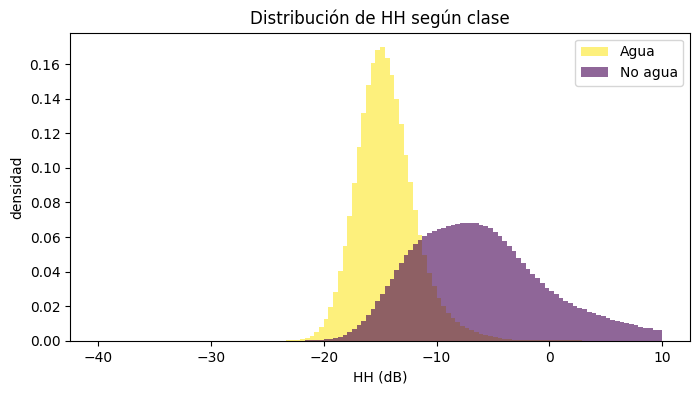

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(hh[valido & (etiqueta == 1)], bins=120, alpha=.6, color="#fde725", label="Agua", density=True, range=(-40, 10))
plt.hist(hh[valido & (etiqueta == 0)], bins=120, alpha=.6, color="#440154", label="No agua", density=True, range=(-40, 10))
plt.xlabel("HH (dB)"); plt.ylabel("densidad"); plt.title("Distribución de HH según clase"); plt.legend()
guardar("03_histograma_hh"); plt.show()

### 2.3 Construcción de variables (features)
Para **Machine Learning** cada píxel será una fila con estas columnas:

| variable | qué es |
|---|---|
| `hh` | backscatter (dB) |
| `hh_med3` | HH con filtro de mediana 3×3 (reduce speckle) |
| `hh_media5` | media local 5×5 |
| `hh_std5` | desviación local 5×5 (textura: agua ≈ lisa) |
| `dem` | elevación |
| `pendiente` | pendiente del terreno (agua ≈ plano) |

In [7]:
def construir_features(hh, dem):
    hh  = np.where(np.isfinite(hh),  hh,  np.nanmedian(hh))
    dem = np.where(np.isfinite(dem), dem, np.nanmedian(dem))
    hh_med3   = median_filter(hh, size=3)
    hh_media5 = uniform_filter(hh, size=5)
    hh_std5   = np.sqrt(np.maximum(uniform_filter(hh**2, size=5) - hh_media5**2, 0))
    gy, gx    = np.gradient(dem, 5 * FACTOR)                 # metros por píxel
    pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))
    return np.stack([hh, hh_med3, hh_media5, hh_std5, dem, pendiente], axis=-1).astype("float32")

NOMBRES = ["hh", "hh_med3", "hh_media5", "hh_std5", "dem", "pendiente"]
feat = construir_features(hh, dem)
print("Tensor de variables:", feat.shape)

Tensor de variables: (2783, 2361, 6)


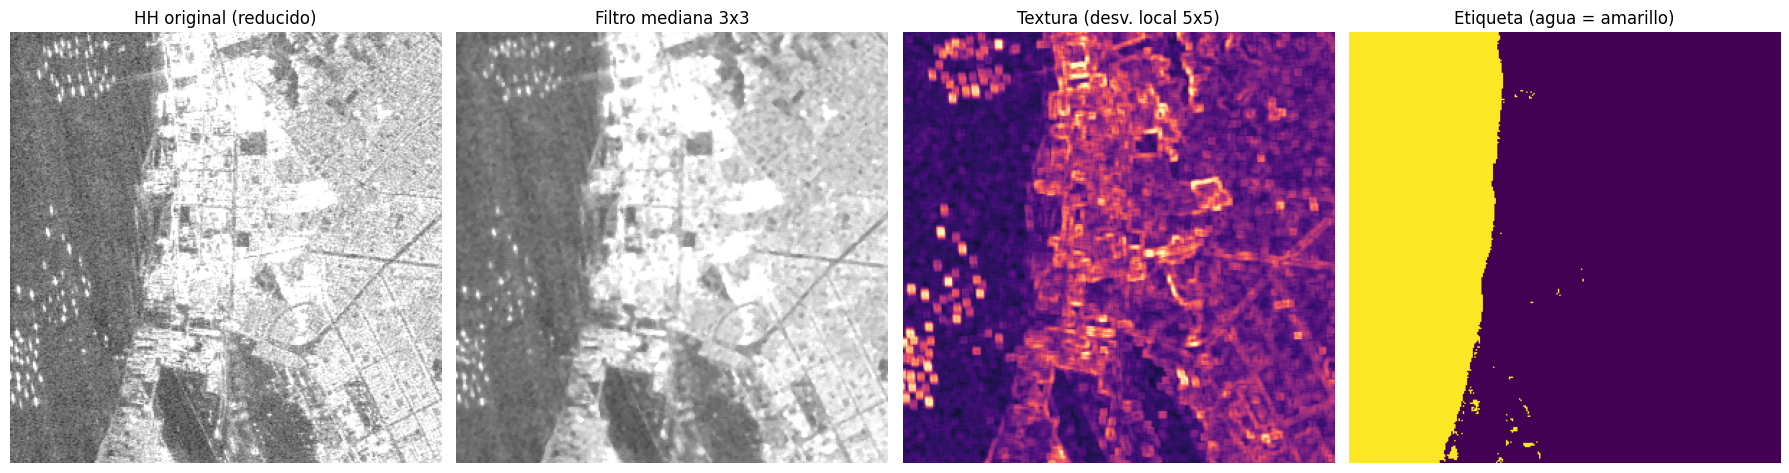

In [8]:
# Efecto visual de los filtros (zoom a una zona con costa y ciudad)
r0, c0, tam = 900, 150, 300
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
ax[0].imshow(feat[r0:r0+tam, c0:c0+tam, 0], cmap="gray", vmin=-25, vmax=0);   ax[0].set_title("HH original (reducido)")
ax[1].imshow(feat[r0:r0+tam, c0:c0+tam, 1], cmap="gray", vmin=-25, vmax=0);   ax[1].set_title("Filtro mediana 3x3")
ax[2].imshow(feat[r0:r0+tam, c0:c0+tam, 3], cmap="magma", vmin=0, vmax=8);    ax[2].set_title("Textura (desv. local 5x5)")
ax[3].imshow(etiqueta[r0:r0+tam, c0:c0+tam], cmap="viridis");                 ax[3].set_title("Etiqueta (agua = amarillo)")
for a in ax: a.axis("off")
plt.tight_layout(); guardar("04_filtros_zoom"); plt.show()

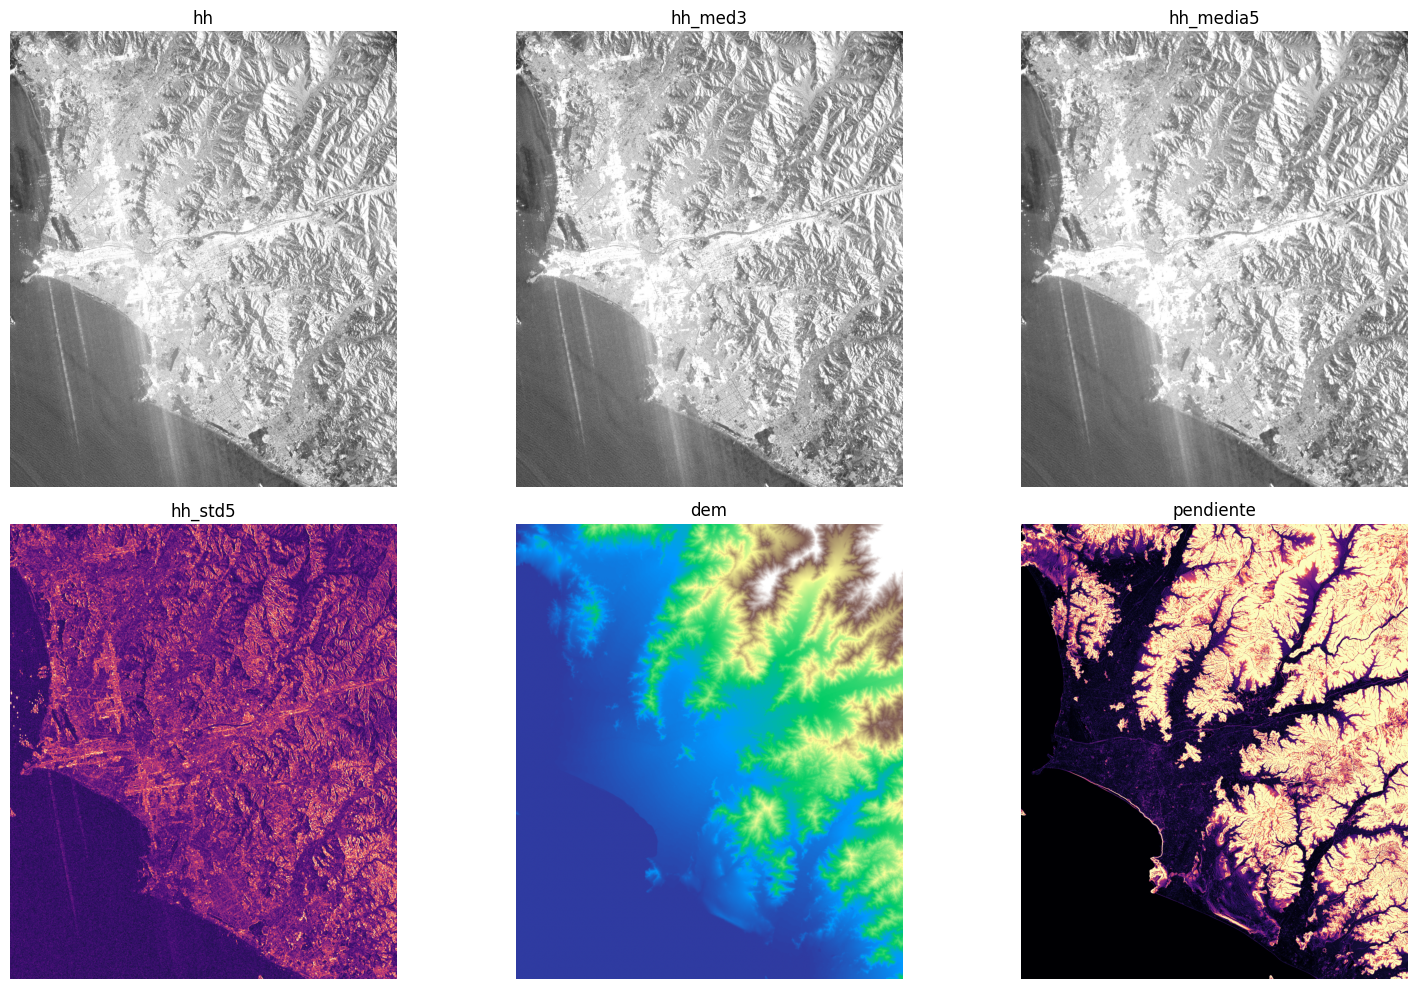

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
vmins = [-25, -25, -25, 0, 0, 0]; vmaxs = [0, 0, 0, 8, np.nanpercentile(dem, 99), 25]
cmaps = ["gray", "gray", "gray", "magma", "terrain", "magma"]
for i, a in enumerate(ax.ravel()):
    a.imshow(feat[..., i], cmap=cmaps[i], vmin=vmins[i], vmax=vmaxs[i]); a.set_title(NOMBRES[i]); a.axis("off")
plt.tight_layout(); guardar("05_variables"); plt.show()

### 2.4 Parches y partición 80 / 20
Si repartiéramos píxeles al azar, un píxel de test tendría vecinos casi idénticos en train (**fuga de información**) y las métricas saldrían infladas.
Por eso cortamos la escena en **parches de 128×128 px (≈ 2.5 km)** y repartimos **parches completos**: 80 % train, 20 % test.
Del train se aparta además un 10 % de parches como validación para monitorear el deep learning.
Machine learning y deep learning usan **exactamente los mismos parches**.

In [10]:
def a_parches(arr):
    h, w = arr.shape[:2]; nh, nw = h // P, w // P
    a = arr[:nh*P, :nw*P]
    if a.ndim == 2: a = a[..., None]
    c = a.shape[2]
    return a.reshape(nh, P, nw, P, c).transpose(0, 2, 1, 3, 4).reshape(nh*nw, P, P, c), nh, nw

def de_parches(p, nh, nw):
    c = p.shape[-1]
    return p.reshape(nh, nw, P, P, c).transpose(0, 2, 1, 3, 4).reshape(nh*P, nw*P, c)

X_p, nh, nw = a_parches(feat)
Y_p, _, _   = a_parches(etiqueta.astype("float32"))
V_p, _, _   = a_parches(valido.astype("float32"))
ok = np.where(V_p.reshape(len(V_p), -1).min(1) == 1)[0]          # solo parches 100% válidos
print(f"Parches totales: {len(X_p)} | válidos: {len(ok)}")

idx_trainval, idx_test = train_test_split(ok, test_size=0.20, random_state=SEED)
idx_train, idx_val     = train_test_split(idx_trainval, test_size=0.10, random_state=SEED)
print(f"train: {len(idx_train)} | val: {len(idx_val)} | test: {len(idx_test)} parches")

Parches totales: 378 | válidos: 378
train: 271 | val: 31 | test: 76 parches


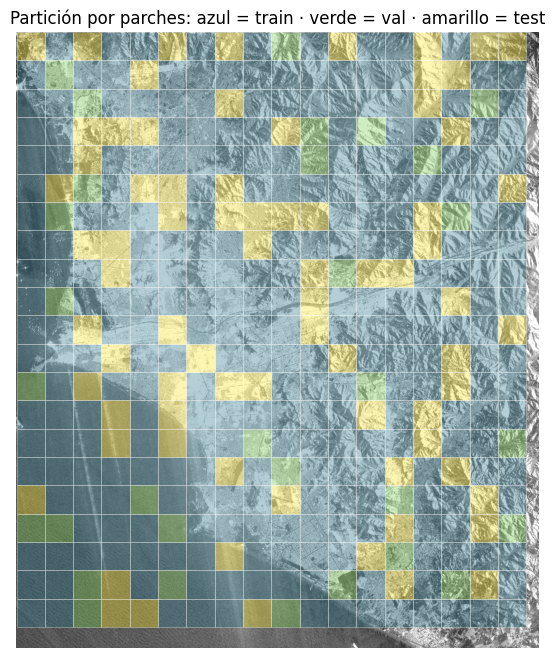

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(feat[..., 0], cmap="gray", vmin=-25, vmax=0)
colores = {}
for i in idx_train: colores[i] = "#2a788e"
for i in idx_val:   colores[i] = "#7ad151"
for i in idx_test:  colores[i] = "#fde725"
for i, col in colores.items():
    f, c = divmod(i, nw)
    ax.add_patch(Rectangle((c*P, f*P), P, P, fill=True, facecolor=col, alpha=.35, edgecolor="white", lw=.6))
ax.set_title("Partición por parches: azul = train · verde = val · amarillo = test"); ax.axis("off")
guardar("06_particion_parches"); plt.show()

### 2.5 Tabla de píxeles para Machine Learning + normalización
Cada parche aporta 128×128 píxeles. Para que los modelos clásicos entrenen rápido se **muestrean 100 000 píxeles** de train (y 150 000 de test).
Luego se **estandariza** (media 0, desviación 1) usando solo estadísticas de train.

In [12]:
rng = np.random.RandomState(SEED)
pix_trainval = np.concatenate([idx_train, idx_val])

Xtr_all = X_p[pix_trainval].reshape(-1, len(NOMBRES));  ytr_all = Y_p[pix_trainval].ravel()
Xte_all = X_p[idx_test].reshape(-1, len(NOMBRES));      yte_all = Y_p[idx_test].ravel()

idx_tr = rng.choice(len(Xtr_all), 100_000, replace=False)
idx_te = rng.choice(len(Xte_all), 150_000, replace=False)     # estos mismos píxeles evaluarán al deep learning

x_train_raw, y_train = Xtr_all[idx_tr], ytr_all[idx_tr].astype(int)
x_test_raw,  y_test  = Xte_all[idx_te], yte_all[idx_te].astype(int)

scaler  = StandardScaler().fit(x_train_raw)
x_train = scaler.transform(x_train_raw)
x_test  = scaler.transform(x_test_raw)
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| % agua train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

df_tabla = pd.DataFrame(x_train_raw[:5], columns=NOMBRES); df_tabla["agua"] = y_train[:5]
df_tabla

x_train: (100000, 6) | x_test: (150000, 6) | % agua train: 0.232 | test: 0.145


,hh,hh_med3,hh_media5,hh_std5,dem,pendiente,agua
0,-12.811006,-14.718534,-15.014070,1.464990,24.762136,0.0,1
1,-16.114119,-15.024318,-14.525002,1.538795,24.762136,0.0,1
2,-15.774303,-14.502172,-15.129519,1.461804,24.762136,0.0,1
3,-18.756269,-16.537167,-16.932917,1.515826,24.762136,0.0,1
4,-15.354998,-15.470380,-15.218240,1.350410,24.762136,0.0,1


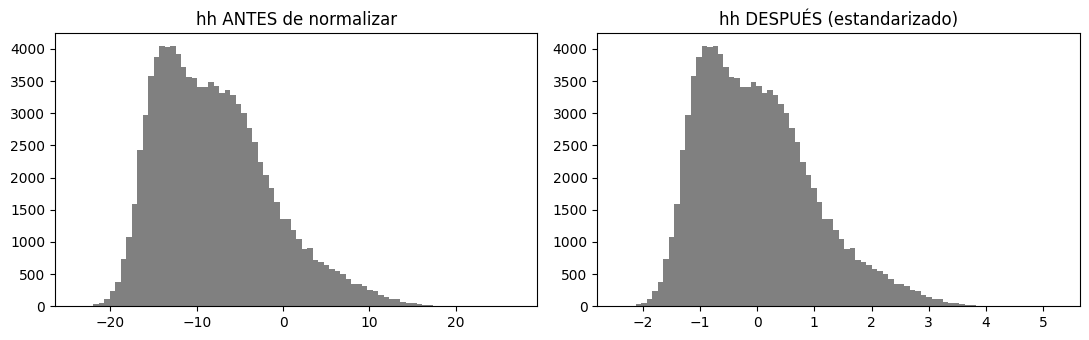

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(x_train_raw[:, 0], bins=80, color="gray"); ax[0].set_title("hh ANTES de normalizar")
ax[1].hist(x_train[:, 0],     bins=80, color="gray"); ax[1].set_title("hh DESPUÉS (estandarizado)")
plt.tight_layout(); guardar("07_normalizacion"); plt.show()

## 3. Modelos de Machine Learning (píxel = fila)
Misma lógica en cada celda: **crear → fit → predict → evaluar**.
La función `evaluar` guarda las métricas en la tabla final (IoU es la métrica principal: *accuracy* engaña porque ~20 % de píxeles son agua).

In [14]:
resultados = []

def evaluar(nombre, familia, y_true, y_pred, y_prob=None, tiempo=np.nan, lista=None):
    lista = resultados if lista is None else lista
    fila = {"Modelo": nombre, "Familia": familia,
            "Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred),
            "IoU":       jaccard_score(y_true, y_pred),
            "AUC":       roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan,
            "Tiempo (s)": round(tiempo, 1)}
    lista.append(fila)
    return pd.DataFrame([fila]).round(4)

In [15]:
t0 = time.time()
logis = LogisticRegression(max_iter=1000)
logis.fit(x_train, y_train)
resp = logis.predict(x_test)
evaluar("Regresión logística", "ML", y_test, resp, logis.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Regresión logística,ML,0.9929,0.9685,0.983,0.9757,0.9526,0.9968,0.4


In [16]:
t0 = time.time()
gnb = GaussianNB()
gnb.fit(x_train, y_train)
resp = gnb.predict(x_test)
evaluar("Naive Bayes", "ML", y_test, resp, gnb.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Naive Bayes,ML,0.9848,0.9305,0.9672,0.9485,0.9021,0.9956,0.2


In [17]:
t0 = time.time()
dt = DecisionTreeClassifier(max_depth=12, random_state=SEED)
dt.fit(x_train, y_train)
resp = dt.predict(x_test)
evaluar("Árbol de decisión", "ML", y_test, resp, dt.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Árbol de decisión,ML,0.9965,0.9933,0.9823,0.9877,0.9758,0.993,2.4


In [18]:
t0 = time.time()
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(x_train, y_train)
resp = knn.predict(x_test)
evaluar("KNN", "ML", y_test, resp, knn.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,KNN,ML,0.9895,0.9623,0.9655,0.9639,0.9303,0.9916,10.0


In [19]:
# SVM es lento (crece ~ n^2), por eso se entrena con una submuestra de 8 000 píxeles
t0 = time.time()
x_svm, y_svm = x_train[:8000], y_train[:8000]
svmc = SVC(kernel="rbf", C=1)
svmc.fit(x_svm, y_svm)
resp = svmc.predict(x_test)
evaluar("SVM (rbf, 8k píxeles)", "ML", y_test, resp, svmc.decision_function(x_test), time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,"SVM (rbf, 8k píxeles)",ML,0.99,0.9576,0.9739,0.9657,0.9336,0.9938,25.6


In [20]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED)
rf.fit(x_train, y_train)
resp = rf.predict(x_test)
evaluar("Random Forest", "ML", y_test, resp, rf.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Random Forest,ML,0.9972,0.9965,0.9844,0.9904,0.981,0.999,10.6


In [21]:
t0 = time.time()
adab = AdaBoostClassifier(n_estimators=100, random_state=SEED)
adab.fit(x_train, y_train)
resp = adab.predict(x_test)
evaluar("AdaBoost", "ML", y_test, resp, adab.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,AdaBoost,ML,0.9973,0.9965,0.9847,0.9906,0.9813,0.9986,34.8


In [22]:
t0 = time.time()
hgb = HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
hgb.fit(x_train, y_train)
resp = hgb.predict(x_test)
evaluar("Hist Gradient Boosting", "ML", y_test, resp, hgb.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Hist Gradient Boosting,ML,0.9973,0.9966,0.985,0.9908,0.9818,0.9993,18.1


In [23]:
t0 = time.time()
xgb = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=SEED)
xgb.fit(x_train, y_train)
resp = xgb.predict(x_test)
evaluar("XGBoost", "ML", y_test, resp, xgb.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,XGBoost,ML,0.9971,0.9968,0.983,0.9898,0.9799,0.9992,1.1


In [24]:
t0 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=60, early_stopping=True, random_state=SEED)
mlp.fit(x_train, y_train)
resp = mlp.predict(x_test)
evaluar("Red neuronal (MLP)", "ML", y_test, resp, mlp.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Red neuronal (MLP),ML,0.9969,0.9965,0.9822,0.9893,0.9788,0.9992,33.5


### 3.1 Optimización ligera (GridSearchCV)
Grilla pequeña sobre Random Forest con 20 000 píxeles y validación cruzada de 3 pliegues, para que no demore.

In [25]:
t0 = time.time()
params = {"n_estimators": [50, 150], "max_depth": [8, 16, None], "min_samples_leaf": [1, 5]}
gs = GridSearchCV(RandomForestClassifier(n_jobs=-1, random_state=SEED), param_grid=params, cv=3, scoring="f1", n_jobs=1, verbose=1)
gs.fit(x_train[:20000], y_train[:20000])
print("Mejores parámetros:", gs.best_params_, "| F1 cv:", round(gs.best_score_, 4))
pd.DataFrame(gs.cv_results_)[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(6)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


Mejores parámetros: {'max_depth': 16, 'min_samples_leaf': 1, 'n_estimators': 50} | F1 cv: 0.9916


,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_test_score
8,50,None,1,0.991622
4,50,16,1,0.991622
5,150,16,1,0.991621
9,150,None,1,0.991621
0,50,8,1,0.991617
1,150,8,1,0.991506


In [26]:
t0 = time.time()
rf_opt = RandomForestClassifier(**gs.best_params_, n_jobs=-1, random_state=SEED)
rf_opt.fit(x_train, y_train)
resp = rf_opt.predict(x_test)
evaluar("Random Forest (optimizado)", "ML", y_test, resp, rf_opt.predict_proba(x_test)[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,Random Forest (optimizado),ML,0.9972,0.9963,0.9843,0.9903,0.9808,0.999,6.1


### 3.2 ¿Qué variables importan? y ¿qué pasa sin DEM?
El DEM hace casi trivial separar el mar (elevación ≈ 0). Para ser honestos con el informe entrenamos también un Random Forest **solo con variables de radar**.

In [27]:
t0 = time.time()
sar = [0, 1, 2, 3]                       # hh, hh_med3, hh_media5, hh_std5
rf_sar = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED)
rf_sar.fit(x_train[:, sar], y_train)
resp = rf_sar.predict(x_test[:, sar])
evaluar("Random Forest (solo radar, sin DEM)", "ML", y_test, resp, rf_sar.predict_proba(x_test[:, sar])[:, 1], time.time() - t0)

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,"Random Forest (solo radar, sin DEM)",ML,0.914,0.7116,0.6833,0.6972,0.5352,0.9531,11.6


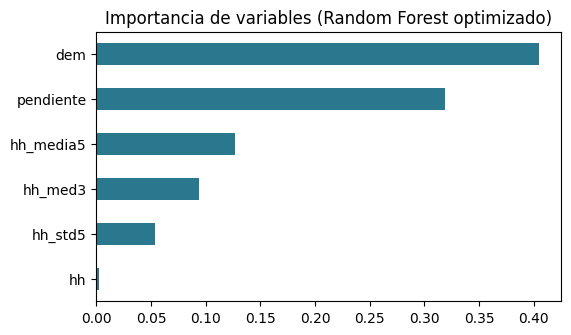

In [28]:
imp = pd.Series(rf_opt.feature_importances_, index=NOMBRES).sort_values()
imp.plot(kind="barh", figsize=(6, 3.5), color="#2a788e", title="Importancia de variables (Random Forest optimizado)")
guardar("08_importancia_variables"); plt.show()

## 4. Deep Learning: U-Net con transfer learning
Aquí la unidad ya no es el píxel sino el **parche 128×128**; la red devuelve la **máscara completa** (segmentación).

* Entrada de 3 canales con sentido físico: **HH, DEM, pendiente** (así encaja con los encoders preentrenados en ImageNet que esperan 3 canales).
* Se prueban: **CNN/U-Net desde cero** (sin transfer learning), **VGG16** y **ResNet50** (encoder preentrenado y congelado + decodificador entrenado).
* Se evalúan sobre **los mismos 150 000 píxeles de test** que los modelos de ML.

train: (813, 128, 128, 3) | val: (31, 128, 128, 3) | test: (76, 128, 128, 3)


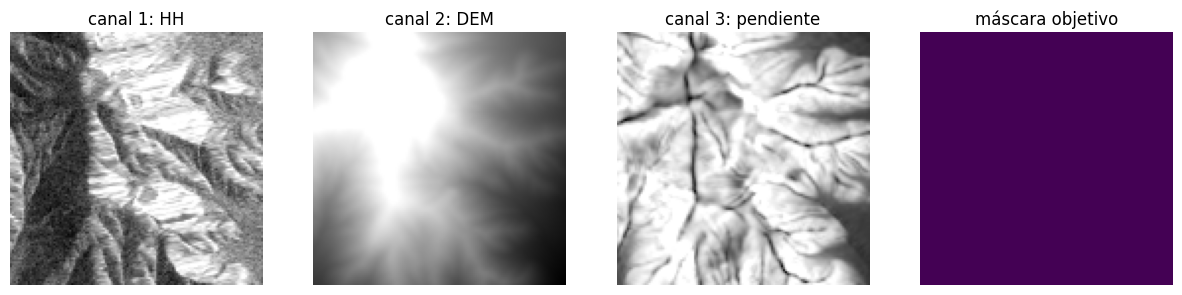

In [29]:
# Canales para DL: hh, dem, pendiente  -> escala 0-255 con percentiles 1-99 calculados solo en train
CANALES = [0, 4, 5]
lo = np.percentile(X_p[idx_train][..., CANALES].reshape(-1, 3), 1,  axis=0)
hi = np.percentile(X_p[idx_train][..., CANALES].reshape(-1, 3), 99, axis=0)

def a_imagen(feat_parches):
    x = (feat_parches[..., CANALES] - lo) / (hi - lo)
    return (np.clip(x, 0, 1) * 255).astype("float32")

def aumentar(x, y):                                   # volteos horizontal y vertical (solo train)
    return (np.concatenate([x, x[:, :, ::-1], x[:, ::-1]]), np.concatenate([y, y[:, :, ::-1], y[:, ::-1]]))

xdl_train, ydl_train = aumentar(a_imagen(X_p[idx_train]), Y_p[idx_train])
xdl_val,   ydl_val   = a_imagen(X_p[idx_val]),  Y_p[idx_val]
xdl_test,  ydl_test  = a_imagen(X_p[idx_test]), Y_p[idx_test]
print("train:", xdl_train.shape, "| val:", xdl_val.shape, "| test:", xdl_test.shape)

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, t, im in zip(ax, ["canal 1: HH", "canal 2: DEM", "canal 3: pendiente"], range(3)):
    a.imshow(xdl_test[0][..., im], cmap="gray"); a.set_title(t); a.axis("off")
ax[3].imshow(ydl_test[0][..., 0], cmap="viridis"); ax[3].set_title("máscara objetivo"); ax[3].axis("off")
guardar("09_entrada_deep_learning"); plt.show()

In [30]:
def bloque(x, f):
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
    return layers.Conv2D(f, 3, padding="same", activation="relu")(x)

def unet_desde_cero():
    ent = keras.Input((P, P, 3))
    e1 = bloque(ent, 16);                              p1 = layers.MaxPool2D()(e1)     # 64
    e2 = bloque(p1, 32);                               p2 = layers.MaxPool2D()(e2)     # 32
    e3 = bloque(p2, 64);                               p3 = layers.MaxPool2D()(e3)     # 16
    b  = bloque(p3, 128)
    d3 = bloque(layers.Concatenate()([layers.UpSampling2D()(b),  e3]), 64)
    d2 = bloque(layers.Concatenate()([layers.UpSampling2D()(d3), e2]), 32)
    d1 = bloque(layers.Concatenate()([layers.UpSampling2D()(d2), e1]), 16)
    return keras.Model(ent, layers.Conv2D(1, 1, activation="sigmoid")(d1), name="UNet_desde_cero")

def unet_transfer(base, skips, cuello, nombre):
    """Encoder preentrenado (congelado) + decodificador U-Net entrenable."""
    base.trainable = False
    x = base.get_layer(cuello).output
    for nom, f in zip(skips, [128, 64, 32][:len(skips)]):
        s = base.get_layer(nom).output
        x = layers.UpSampling2D()(x)
        x = bloque(layers.Concatenate()([x, s]), f)
    while x.shape[1] < P:                              # si el último skip no está a resolución completa
        x = bloque(layers.UpSampling2D()(x), 16)
    return keras.Model(base.input, layers.Conv2D(1, 1, activation="sigmoid")(x), name=nombre)

def entrenar(modelo, x_tr, y_tr, x_va, y_va, epocas, lr=1e-3):
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                   metrics=[keras.metrics.BinaryIoU(name="iou", target_class_ids=[1])])
    return modelo.fit(x_tr, y_tr, validation_data=(x_va, y_va), epochs=epocas, batch_size=8, verbose=2)

def prediccion_dl(modelo, x):
    """Probabilidades en todos los parches -> vector evaluado sobre los MISMOS píxeles del ML."""
    return modelo.predict(x, batch_size=16, verbose=0)

### 4.1 CNN / U-Net desde cero (sin transfer learning)

In [31]:
t0 = time.time()
modelo_cnn = unet_desde_cero()
modelo_cnn.summary()
hist_cnn = entrenar(modelo_cnn, xdl_train / 255, ydl_train, xdl_val / 255, ydl_val, epocas=8)
prob_cnn = prediccion_dl(modelo_cnn, xdl_test / 255)
resp = (prob_cnn.ravel()[idx_te] > 0.5).astype(int)
evaluar("U-Net desde cero (CNN)", "DL", y_test, resp, prob_cnn.ravel()[idx_te], time.time() - t0)

Model: "UNet_desde_cero"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]  

 Total params: 487,297 (1.86 MB)

 Trainable params: 487,297 (1.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8


... (12 outputs left out)

102/102 - 37s - 360ms/step - iou: 0.9811 - loss: 0.0176 - val_iou: 0.9894 - val_loss: 0.0190


Epoch 8/8


102/102 - 36s - 356ms/step - iou: 0.9818 - loss: 0.0165 - val_iou: 0.9890 - val_loss: 0.0241


,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,U-Net desde cero (CNN),DL,0.9976,0.9986,0.985,0.9918,0.9837,0.9992,324.4


### 4.2 U-Net con encoder VGG16 (transfer learning, pesos ImageNet)

In [32]:
t0 = time.time()
base_vgg = VGG16(include_top=False, weights="imagenet", input_shape=(P, P, 3))
modelo_vgg = unet_transfer(base_vgg, skips=["block3_conv3", "block2_conv2", "block1_conv2"],
                           cuello="block4_conv3", nombre="UNet_VGG16")
print("Parámetros entrenables:", f"{sum(int(np.prod(w.shape)) for w in modelo_vgg.trainable_weights):,}",
      "| congelados:", f"{sum(int(np.prod(w.shape)) for w in modelo_vgg.non_trainable_weights):,}")
hist_vgg = entrenar(modelo_vgg, prep_vgg(xdl_train.copy()), ydl_train, prep_vgg(xdl_val.copy()), ydl_val, epocas=5)
prob_vgg = prediccion_dl(modelo_vgg, prep_vgg(xdl_test.copy()))
resp = (prob_vgg.ravel()[idx_te] > 0.5).astype(int)
evaluar("U-Net + VGG16 (transfer)", "DL", y_test, resp, prob_vgg.ravel()[idx_te], time.time() - t0)

Parámetros entrenables: 1,263,073 | congelados: 7,635,264


Epoch 1/5


102/102 - 205s - 2s/step - iou: 0.6844 - loss: 10.3529 - val_iou: 0.8698 - val_loss: 0.4477


Epoch 2/5


102/102 - 253s - 2s/step - iou: 0.8768 - loss: 0.3133 - val_iou: 0.9231 - val_loss: 0.1540


Epoch 3/5


... (2 outputs left out)

102/102 - 258s - 3s/step - iou: 0.9357 - loss: 0.1123 - val_iou: 0.9677 - val_loss: 0.0601


Epoch 5/5


102/102 - 217s - 2s/step - iou: 0.9444 - loss: 0.0897 - val_iou: 0.9710 - val_loss: 0.0540


,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,U-Net + VGG16 (transfer),DL,0.9908,0.9519,0.9864,0.9689,0.9396,0.9978,1213.9


### 4.3 U-Net con encoder ResNet50 (transfer learning)
Usa los pesos ImageNet de ResNet50 (~98 MB, se descargan la primera vez). Con `USAR_RESNET50 = False` se omite esta sección.

In [33]:
USAR_RESNET50 = True

if USAR_RESNET50:
    t0 = time.time()
    base_res = ResNet50(include_top=False, weights="imagenet", input_shape=(P, P, 3))
    modelo_res = unet_transfer(base_res, skips=["conv3_block4_out", "conv2_block3_out", "conv1_relu"],
                               cuello="conv4_block6_out", nombre="UNet_ResNet50")
    hist_res = entrenar(modelo_res, prep_resnet(xdl_train.copy()), ydl_train, prep_resnet(xdl_val.copy()), ydl_val, epocas=5)
    prob_res = prediccion_dl(modelo_res, prep_resnet(xdl_test.copy()))
    resp = (prob_res.ravel()[idx_te] > 0.5).astype(int)
    display(evaluar("U-Net + ResNet50 (transfer)", "DL", y_test, resp, prob_res.ravel()[idx_te], time.time() - t0))
else:
    print("ResNet50 omitido (USAR_RESNET50 = True).")

       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 5:38 4us/step

   81920/94765736 ━━━━━━━━━━━━━━━━━━━━ 6:48 4us/step

  122880/94765736 ━━━━━━━━━━━━━━━━━━━━ 5:12 3us/step

  163840/94765736 ━━━━━━━━━━━━━━━━━━━━ 4:32 3us/step

  196608/94765736 ━━━━━━━━━━━━━━━━━━━━ 4:13 3us/step

... (116 outputs left out)

102/102 - 82s - 808ms/step - iou: 0.9678 - loss: 0.0255 - val_iou: 0.9879 - val_loss: 0.0172


Epoch 5/5


102/102 - 91s - 889ms/step - iou: 0.9736 - loss: 0.0210 - val_iou: 0.9890 - val_loss: 0.0227


,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,U-Net + ResNet50 (transfer),DL,0.9955,0.9855,0.9834,0.9845,0.9694,0.9993,569.7


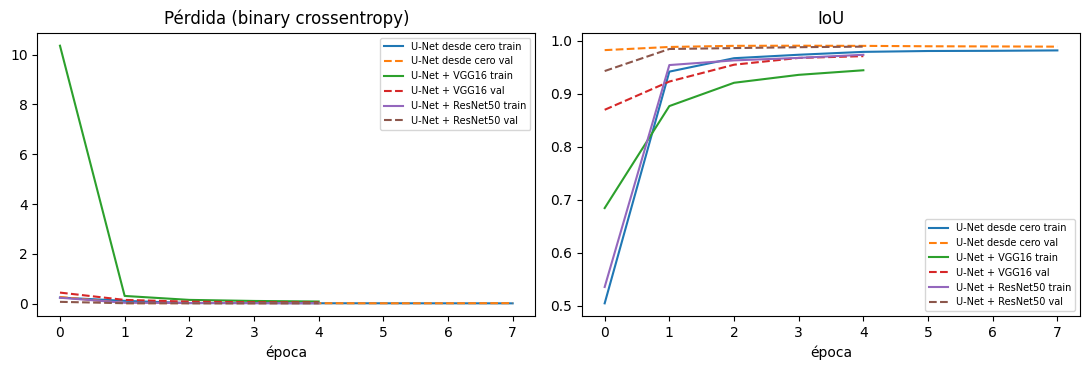

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
modelos_hist = [("U-Net desde cero", hist_cnn), ("U-Net + VGG16", hist_vgg)]
if USAR_RESNET50: modelos_hist.append(("U-Net + ResNet50", hist_res))
for nombre, h in modelos_hist:
    ax[0].plot(h.history["loss"], label=f"{nombre} train"); ax[0].plot(h.history["val_loss"], "--", label=f"{nombre} val")
    ax[1].plot(h.history["iou"], label=f"{nombre} train");  ax[1].plot(h.history["val_iou"], "--", label=f"{nombre} val")
ax[0].set_title("Pérdida (binary crossentropy)"); ax[1].set_title("IoU"); ax[0].set_xlabel("época"); ax[1].set_xlabel("época")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); guardar("10_curvas_aprendizaje"); plt.show()

## 5. Comparación final: Machine Learning vs Deep Learning (test en Lima)

In [35]:
tabla = pd.DataFrame(resultados).sort_values("IoU", ascending=False).reset_index(drop=True).round(4)
tabla.to_csv(CARPETA_FIG / "tabla_resultados_lima.csv", index=False)
tabla

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC,Tiempo (s)
0,U-Net desde cero (CNN),DL,0.9976,0.9986,0.9850,0.9918,0.9837,0.9992,324.4
1,Hist Gradient Boosting,ML,0.9973,0.9966,0.9850,0.9908,0.9818,0.9993,18.1
2,AdaBoost,ML,0.9973,0.9965,0.9847,0.9906,0.9813,0.9986,34.8
3,Random Forest,ML,0.9972,0.9965,0.9844,0.9904,0.9810,0.9990,10.6
4,Random Forest (optimizado),ML,0.9972,0.9963,0.9843,0.9903,0.9808,0.9990,6.1
5,XGBoost,ML,0.9971,0.9968,0.9830,0.9898,0.9799,0.9992,1.1
6,Red neuronal (MLP),ML,0.9969,0.9965,0.9822,0.9893,0.9788,0.9992,33.5
7,Árbol de decisión,ML,0.9965,0.9933,0.9823,0.9877,0.9758,0.9930,2.4
8,U-Net + ResNet50 (transfer),DL,0.9955,0.9855,0.9834,0.9845,0.9694,0.9993,569.7
9,Regresión logística,ML,0.9929,0.9685,0.9830,0.9757,0.9526,0.9968,0.4


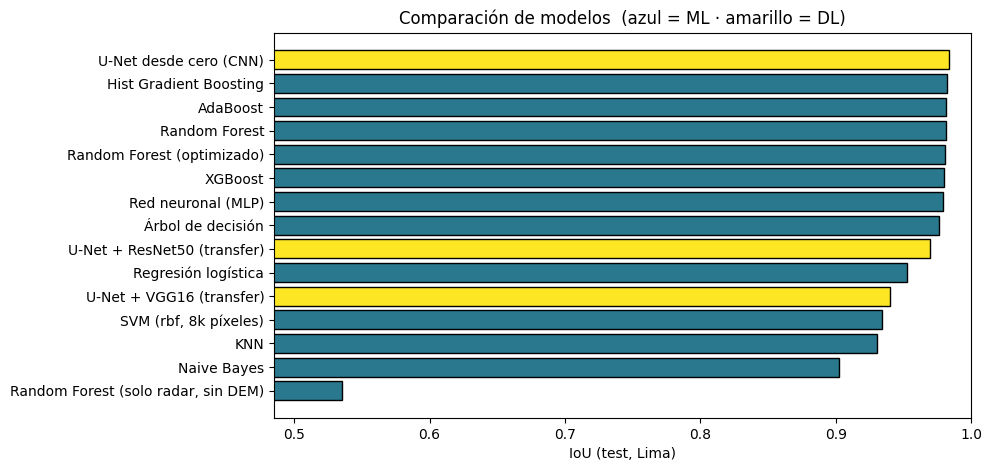

         Accuracy  Precision  Recall      F1     IoU
Familia                                             
DL         0.9976     0.9986  0.9864  0.9918  0.9837
ML         0.9973     0.9968  0.9850  0.9908  0.9818


In [36]:
colores = tabla["Familia"].map({"ML": "#2a788e", "DL": "#fde725"})
plt.figure(figsize=(9, 5))
plt.barh(tabla["Modelo"][::-1], tabla["IoU"][::-1], color=colores[::-1], edgecolor="k")
plt.xlabel("IoU (test, Lima)"); plt.title("Comparación de modelos  (azul = ML · amarillo = DL)"); plt.xlim(tabla["IoU"].min() - 0.05, 1)
guardar("11_comparacion_iou"); plt.show()
print(tabla.groupby("Familia")[["Accuracy", "Precision", "Recall", "F1", "IoU"]].max().round(4))

### 5.1 Mapas predichos (morado = no agua · amarillo = agua)

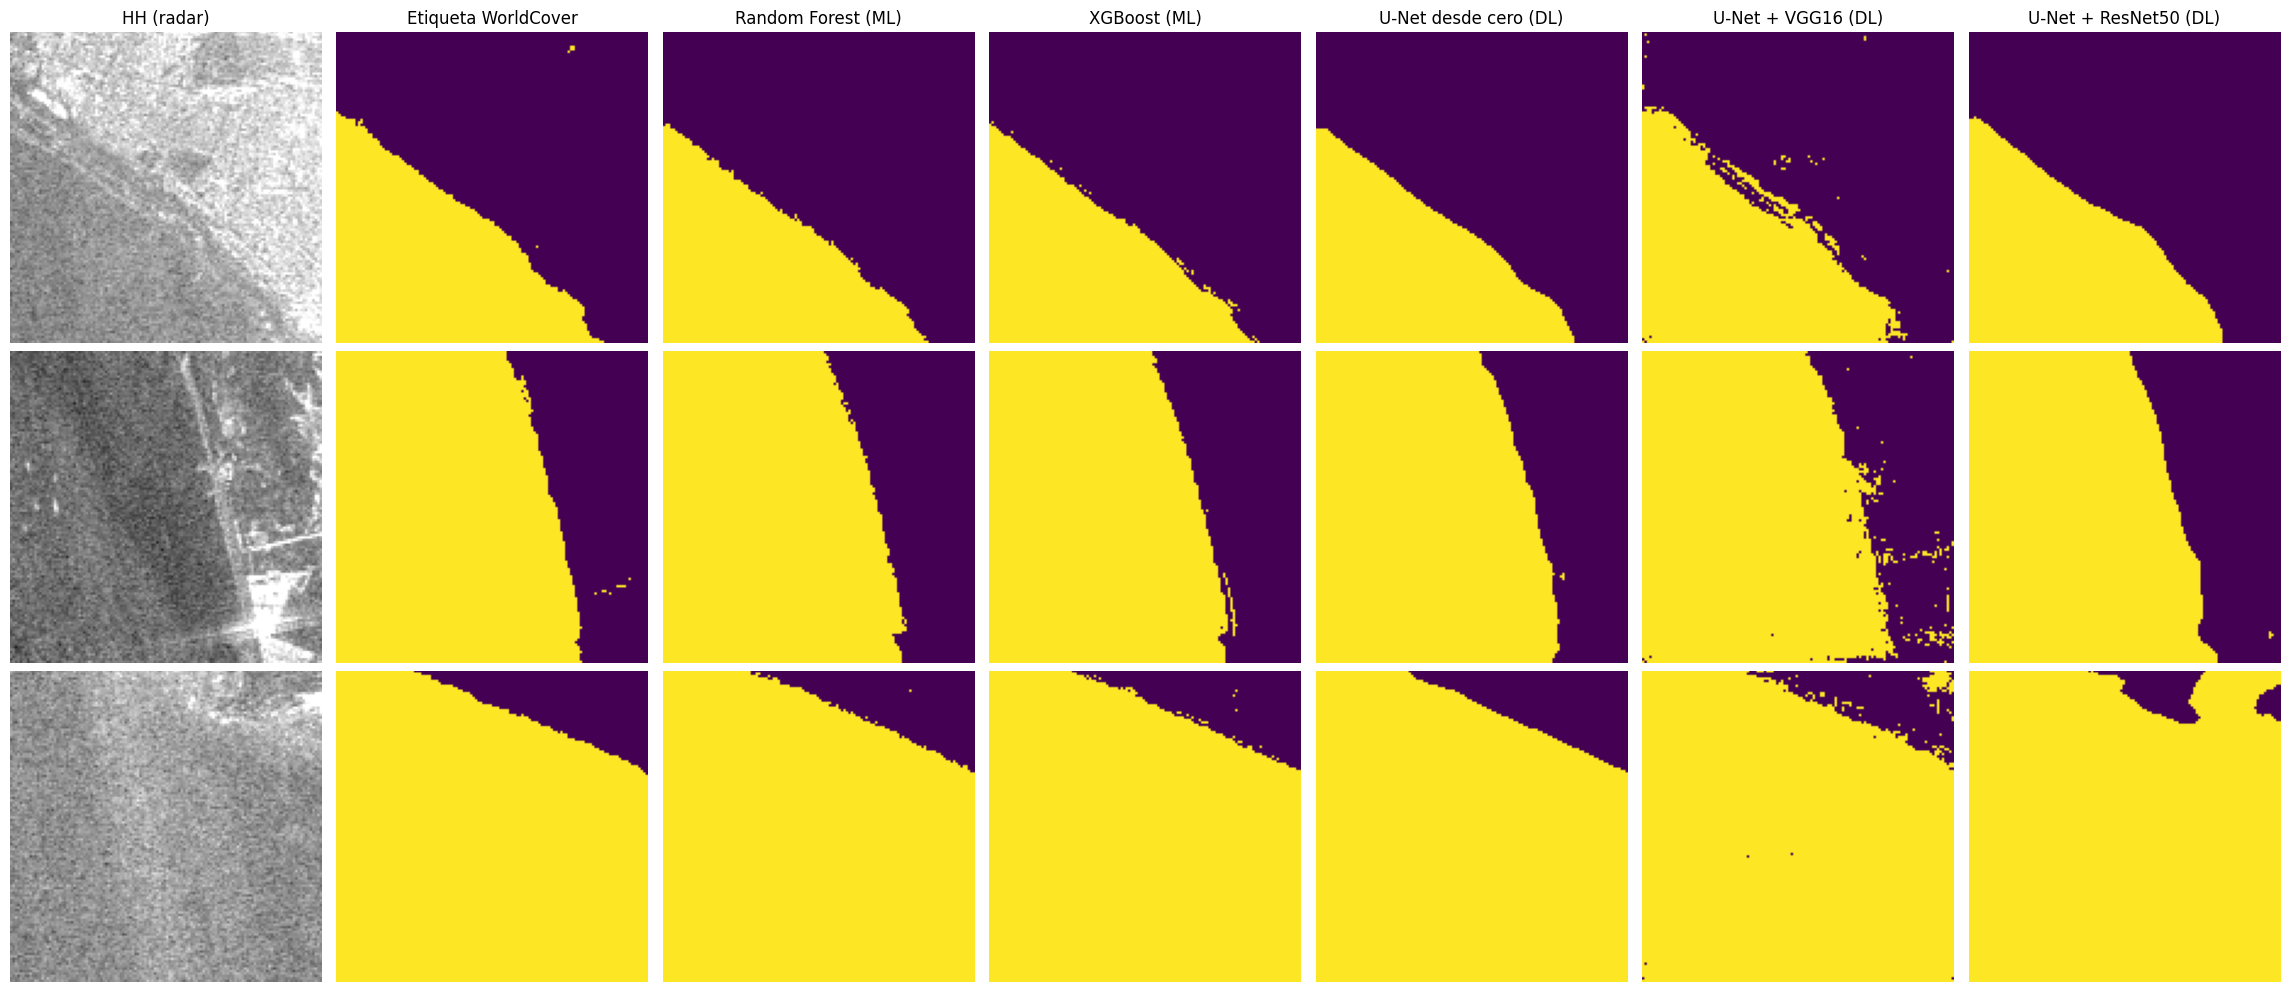

In [37]:
def predecir_ml(modelo, feat_parches):
    s = feat_parches.shape
    p = modelo.predict_proba(scaler.transform(feat_parches.reshape(-1, s[-1])))[:, 1]
    return p.reshape(s[:-1])

# parches de test "mixtos" (cerca de 50% agua): costa, ríos, zonas donde sí hay que decidir
frac_agua = Y_p[idx_test].mean(axis=(1, 2, 3))
orden_k = np.argsort(np.abs(frac_agua - 0.5))[:3]
fig, ax = plt.subplots(3, 7 if USAR_RESNET50 else 6, figsize=(23 if USAR_RESNET50 else 20, 10))
for fila, k in enumerate(orden_k):
    i = idx_test[k]
    mapas = [("HH (radar)", X_p[i][..., 0], "gray"),
             ("Etiqueta WorldCover", Y_p[i][..., 0], "viridis"),
             ("Random Forest (ML)", predecir_ml(rf_opt, X_p[i][None])[0] > 0.5, "viridis"),
             ("XGBoost (ML)", predecir_ml(xgb, X_p[i][None])[0] > 0.5, "viridis"),
             ("U-Net desde cero (DL)", prob_cnn[k][..., 0] > 0.5, "viridis"),
             ("U-Net + VGG16 (DL)", prob_vgg[k][..., 0] > 0.5, "viridis")]
    if USAR_RESNET50: mapas.append(("U-Net + ResNet50 (DL)", prob_res[k][..., 0] > 0.5, "viridis"))
    for col, (t, m, cm) in enumerate(mapas):
        ax[fila, col].imshow(m, cmap=cm, **({"vmin": -25, "vmax": 0} if cm == "gray" else {"vmin": 0, "vmax": 1}))
        ax[fila, col].axis("off")
        if fila == 0: ax[fila, col].set_title(t)
plt.tight_layout(); guardar("12_mapas_predichos"); plt.show()

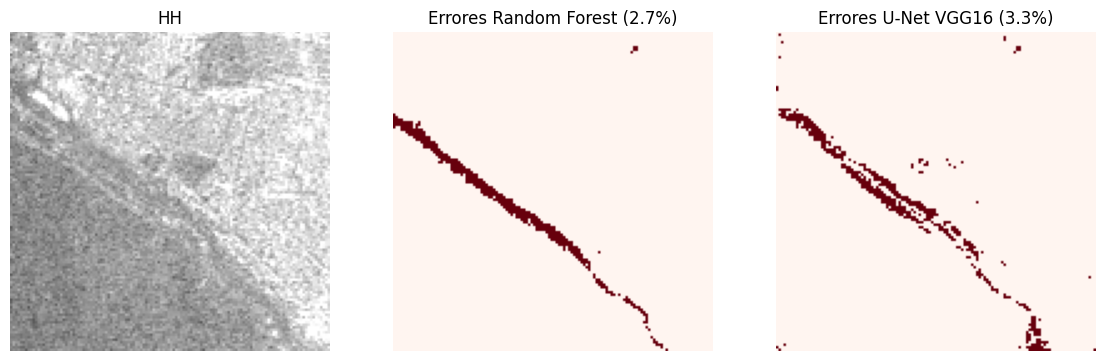

In [38]:
# Mapa de ERRORES del mejor modelo ML y del mejor DL en un parche de test (rojo = se equivocó)
k = orden_k[0]; i = idx_test[k]
pred_ml = predecir_ml(rf_opt, X_p[i][None])[0] > 0.5
pred_dl = prob_vgg[k][..., 0] > 0.5
real = Y_p[i][..., 0] > 0.5
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
ax[0].imshow(X_p[i][..., 0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title("HH")
ax[1].imshow(pred_ml != real, cmap="Reds"); ax[1].set_title(f"Errores Random Forest ({(pred_ml != real).mean():.1%})")
ax[2].imshow(pred_dl != real, cmap="Reds"); ax[2].set_title(f"Errores U-Net VGG16 ({(pred_dl != real).mean():.1%})")
for a in ax: a.axis("off")
guardar("13_mapas_errores"); plt.show()

## 6. Prueba externa en Tumbes
Tumbes es otra ciudad, otro clima y otra geometría; **ningún modelo la vio en entrenamiento ni en validación**.
Es la prueba real de generalización. Se usa la misma normalización (scaler y percentiles de Lima).

In [39]:
hh_t, dem_t, wc_t = leer_zona("tumbes", "20261024")
feat_t = construir_features(hh_t, dem_t)
et_t   = (wc_t == 80).astype("float32")
val_t  = (np.isfinite(hh_t) & np.isfinite(dem_t)).astype("float32")

Xt_p, nh_t, nw_t = a_parches(feat_t); Yt_p, _, _ = a_parches(et_t); Vt_p, _, _ = a_parches(val_t)
ok_t = np.where(Vt_p.reshape(len(Vt_p), -1).min(1) == 1)[0]
Xt_p, Yt_p = Xt_p[ok_t], Yt_p[ok_t]
print("Parches válidos en Tumbes:", len(ok_t))

rng = np.random.RandomState(SEED)
Xt_all = Xt_p.reshape(-1, len(NOMBRES)); yt_all = Yt_p.ravel().astype(int)
idx_t  = rng.choice(len(Xt_all), min(150_000, len(Xt_all)), replace=False)
xt_test, yt_test = scaler.transform(Xt_all[idx_t]), yt_all[idx_t]
xdl_t = a_imagen(Xt_p)
print("% agua Tumbes:", yt_test.mean().round(3))

Parches válidos en Tumbes: 84


% agua Tumbes: 0.201


In [40]:
resultados_ext = []
t = np.nan
evaluar("Regresión logística", "ML", yt_test, logis.predict(xt_test), logis.predict_proba(xt_test)[:, 1], t, resultados_ext)
evaluar("Árbol de decisión",   "ML", yt_test, dt.predict(xt_test),    dt.predict_proba(xt_test)[:, 1],    t, resultados_ext)
evaluar("Random Forest (optimizado)", "ML", yt_test, rf_opt.predict(xt_test), rf_opt.predict_proba(xt_test)[:, 1], t, resultados_ext)
evaluar("Random Forest (solo radar, sin DEM)", "ML", yt_test, rf_sar.predict(xt_test[:, sar]), rf_sar.predict_proba(xt_test[:, sar])[:, 1], t, resultados_ext)
evaluar("XGBoost",             "ML", yt_test, xgb.predict(xt_test),   xgb.predict_proba(xt_test)[:, 1],   t, resultados_ext)
evaluar("Hist Gradient Boosting", "ML", yt_test, hgb.predict(xt_test), hgb.predict_proba(xt_test)[:, 1], t, resultados_ext)

p_cnn_t = prediccion_dl(modelo_cnn, xdl_t / 255).ravel()[idx_t]
evaluar("U-Net desde cero (CNN)", "DL", yt_test, (p_cnn_t > 0.5).astype(int), p_cnn_t, t, resultados_ext)
p_vgg_t = prediccion_dl(modelo_vgg, prep_vgg(xdl_t.copy())).ravel()[idx_t]
evaluar("U-Net + VGG16 (transfer)", "DL", yt_test, (p_vgg_t > 0.5).astype(int), p_vgg_t, t, resultados_ext)

if USAR_RESNET50:
    p_res_t = prediccion_dl(modelo_res, prep_resnet(xdl_t.copy())).ravel()[idx_t]
    evaluar("U-Net + ResNet50 (transfer)", "DL", yt_test, (p_res_t > 0.5).astype(int), p_res_t, t, resultados_ext)

tabla_ext = pd.DataFrame(resultados_ext).drop(columns="Tiempo (s)").sort_values("IoU", ascending=False).reset_index(drop=True).round(4)
tabla_ext.to_csv(CARPETA_FIG / "tabla_resultados_tumbes.csv", index=False)
tabla_ext

,Modelo,Familia,Accuracy,Precision,Recall,F1,IoU,AUC
0,U-Net + ResNet50 (transfer),DL,0.9299,0.8017,0.8661,0.8327,0.7133,0.9712
1,U-Net desde cero (CNN),DL,0.9183,0.7446,0.9047,0.8169,0.6904,0.9749
2,XGBoost,ML,0.8787,0.6502,0.8595,0.7403,0.5877,0.9385
3,"Random Forest (solo radar, sin DEM)",ML,0.8774,0.7322,0.6165,0.6694,0.5031,0.9075
4,Regresión logística,ML,0.8098,0.5149,0.9472,0.6672,0.5006,0.9559
5,U-Net + VGG16 (transfer),DL,0.8243,0.5403,0.8525,0.6614,0.4941,0.9188
6,Árbol de decisión,ML,0.7888,0.4857,0.8352,0.6142,0.4432,0.7677
7,Random Forest (optimizado),ML,0.7446,0.4403,0.9914,0.6098,0.4386,0.9668
8,Hist Gradient Boosting,ML,0.7128,0.4116,0.9939,0.5821,0.4106,0.9786


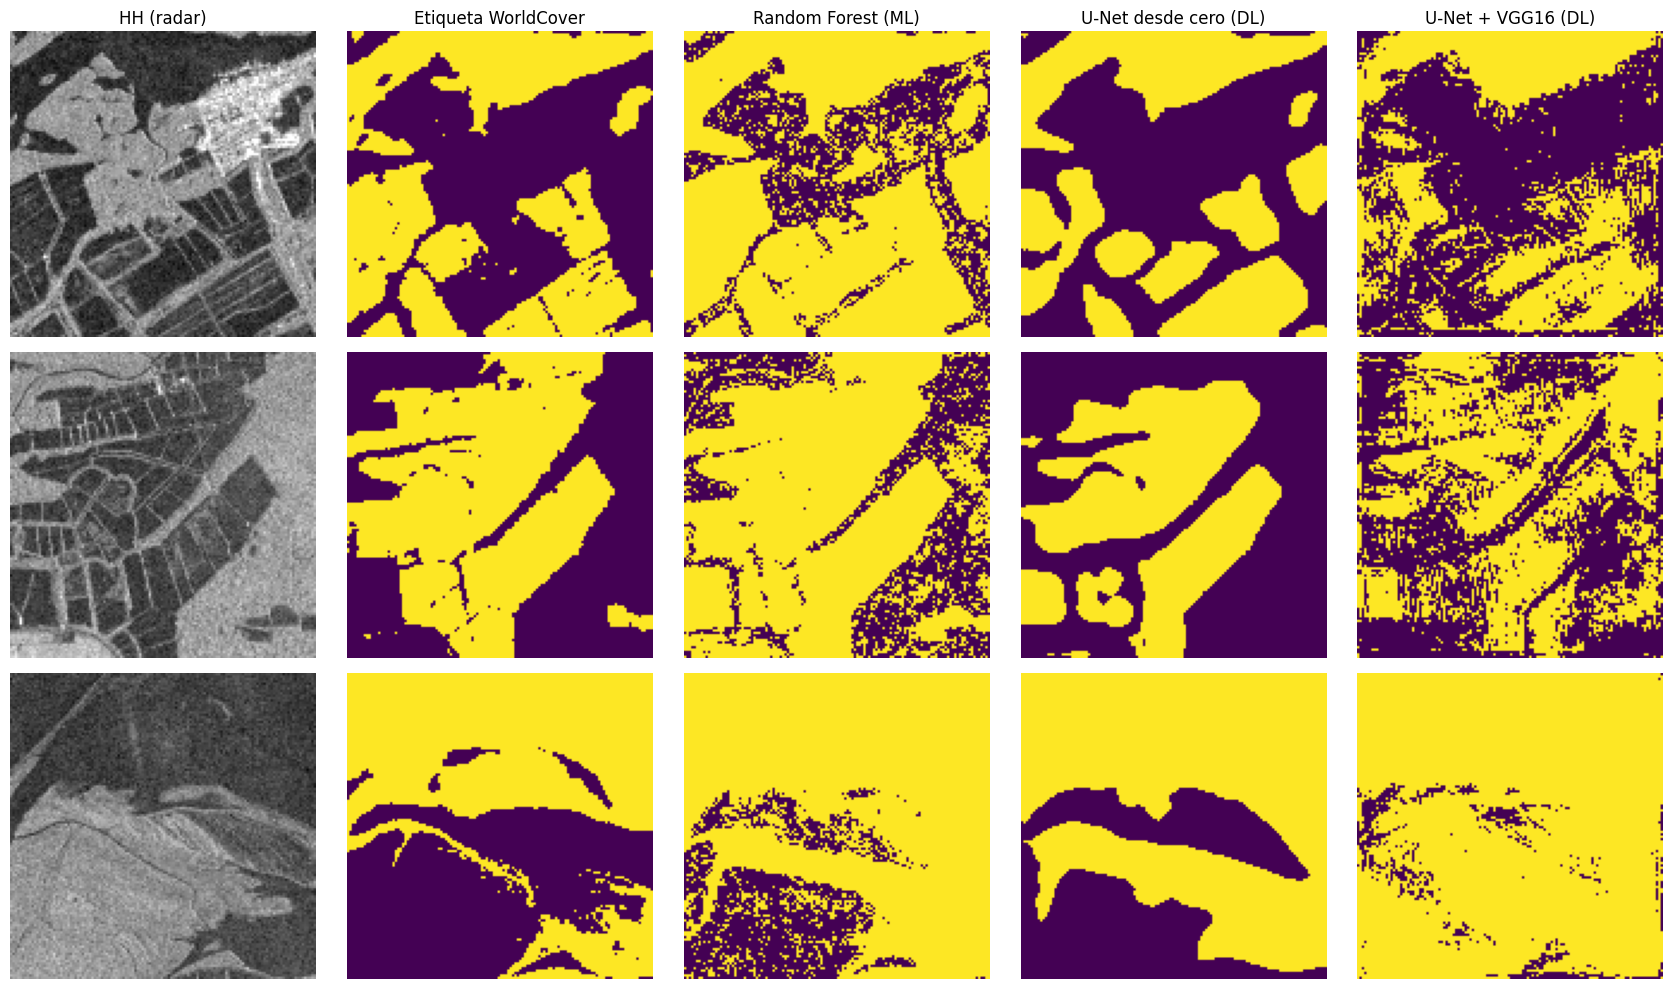

In [41]:
# Mapas de Tumbes (3 parches mixtos, cerca de 50% agua)
orden = np.argsort(np.abs(Yt_p.reshape(len(Yt_p), -1).mean(1) - 0.5))[:3]
fig, ax = plt.subplots(3, 5, figsize=(17, 10))
for fila, i in enumerate(orden):
    pv = prediccion_dl(modelo_vgg, prep_vgg(xdl_t[i][None].copy()))[0, ..., 0] > 0.5
    pc = prediccion_dl(modelo_cnn, xdl_t[i][None] / 255)[0, ..., 0] > 0.5
    mapas = [("HH (radar)", Xt_p[i][..., 0], "gray"), ("Etiqueta WorldCover", Yt_p[i][..., 0], "viridis"),
             ("Random Forest (ML)", predecir_ml(rf_opt, Xt_p[i][None])[0] > 0.5, "viridis"),
             ("U-Net desde cero (DL)", pc, "viridis"), ("U-Net + VGG16 (DL)", pv, "viridis")]
    for col, (tt, m, cm) in enumerate(mapas):
        ax[fila, col].imshow(m, cmap=cm, **({"vmin": -25, "vmax": 0} if cm == "gray" else {"vmin": 0, "vmax": 1}))
        ax[fila, col].axis("off")
        if fila == 0: ax[fila, col].set_title(tt)
plt.tight_layout(); guardar("14_mapas_tumbes"); plt.show()

## 7. Conclusiones (completar con los resultados de arriba)
* ¿Qué familia ganó en Lima (test) y en Tumbes (externa)?
* ¿Cuánto cae el rendimiento sin DEM (solo radar)?
* ¿Dónde fallan los modelos (bordes, ríos angostos, zonas urbanas)? → ver mapas de error.
* **Siguiente etapa:** pasar de *agua superficial* a *agua de lluvia / inundación nueva* (cambio respecto a escenas secas) y afinar hiperparámetros.